In [15]:
import os
import numpy as np  # Импортируем библиотеку NumPy для работы с массивами чисел
import pandas as pd  # Импортируем Pandas для загрузки и анализа табличных данных
import torch  # Импортируем сам фреймворк PyTorch для построения нейросетей
import torch.nn as nn  # Импортируем модуль готовых слоев нейросетей (Linear, и т.д.)
import torch.optim as optim  # Импортируем модуль с алгоритмами оптимизации (SGD, Adam)
from sklearn.metrics import (
    r2_score,
)  # Импортируем функцию расчета метрики R2 из scikit-learn
from sklearn.model_selection import (
    train_test_split,
)  # Импортируем функцию разделения выборки на train/test
from sklearn.preprocessing import (
    StandardScaler,
)  # Импортируем инструмент для стандартизации (масштабирования) признаков

# Загружаем датасет из CSV-файла в таблицу Pandas DataFrame
current_dir = os.path.dirname(os.path.abspath('__file__'))
path_to_file = os.path.join(current_dir, 'Fish.csv')
df = pd.read_csv(path_to_file)

# Создаем матрицу признаков X, удаляя из исходной таблицы целевую колонку Weight
X = df.drop(columns=["Weight"])

# Выделяем целевую переменную y (вес рыбы), переводим в массив NumPy и тип float32
y = df["Weight"].values.astype(np.float32)

# Преобразуем текстовую колонку Species в бинарные признаки (0 и 1) через One-Hot Encoding
X = pd.get_dummies(X, columns=["Species"], drop_first=True)

# Переводим готовую таблицу признаков в чистый массив NumPy с типом данных float32
X = X.values.astype(np.float32)

# Делим данные: 80% на обучение, 20% на тест. Задаем random_state для воспроизводимости
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Создаем объект StandardScaler для приведения признаков к среднему 0 и отклонению 1
scaler = StandardScaler()

# На основе обучающей выборки считаем среднее/std и сразу же масштабируем её
X_train = scaler.fit_transform(X_train)

# Применяем те же самые параметры масштабирования (среднее и std) к тестовой выборке
X_test = scaler.transform(X_test)

# Конвертируем обучающие признаки из массива NumPy в тензор PyTorch
X_train_t = torch.tensor(X_train)

# Конвертируем обучающие ответы в тензор и добавляем размерность (из [N] делаем [N, 1])
y_train_t = torch.tensor(y_train).unsqueeze(1)

# Конвертируем тестовые признаки из массива NumPy в тензор PyTorch
X_test_t = torch.tensor(X_test)

# Конвертируем тестовые ответы в тензор и тоже добавляем размерность до [N, 1]
y_test_t = torch.tensor(y_test).unsqueeze(1)

# Считаем количество входных признаков (количество колонок в нашей матрице X)
input_dim = X_train.shape[1]

# Создаем однослойный персептрон: линейный слой с input_dim входами и 1 выходом
model = nn.Linear(input_dim, 1)

# Задаем функцию потерь MSE (Mean Squared Error) для задачи регрессии
criterion = nn.MSELoss()

# Инициализируем оптимизатор SGD, передаем ему веса модели и скорость обучения (lr)
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Задаем количество полных проходов по обучающему датасету (эпох)
epochs = 2000

# Запускаем цикл обучения
for epoch in range(epochs):
    # Переводим модель в режим обучения (включает вычисление градиентов)
    model.train()

    # Делаем предсказание: пропускаем признаки через веса линейного слоя (Forward pass)
    predictions = model(X_train_t)

    # Вычисляем величину ошибки (MSE) между предсказаниями и реальными весами рыб
    loss = criterion(predictions, y_train_t)

    # Очищаем градиенты прошлых шагов, чтобы они не накапливались
    optimizer.zero_grad()

    # Считаем градиенты ошибки по всем весам модели (Backward pass)
    loss.backward()

    # Делаем шаг оптимизатора: обновляем веса модели в сторону уменьшения ошибки
    optimizer.step()

    # Каждые 400 эпох выводим текущий прогресс на экран
    if (epoch + 1) % 400 == 0:
        # Печатаем номер эпохи и текущее значение функции потерь
       print(f"Эпоха [{epoch+1}/{epochs}], Ошибка (MSE): {loss.item():.4f}")

# Переводим модель в режим оценки (выключает специфичные для обучения слои)
model.eval()

# Отключаем автоматическое отслеживание и расчет градиентов для экономии памяти
with torch.no_grad():
    # Пропускаем тестовые признаки через обученную модель для получения прогнозов
    y_pred_t = model(X_test_t)

    # Переводим тензор предсказаний обратно в обычный массив NumPy
    y_pred = y_pred_t.numpy()

# Рассчитываем итоговую метрику R2 (коэффициент детерминации) на тесте
r2 = r2_score(y_test, y_pred)

# Выводим финальный результат работы нашей нейросети
print(f"\nРезультат R2 на тестовой выборке: {r2:.4f}")




Эпоха [400/2000], Ошибка (MSE): 9758.5381
Эпоха [800/2000], Ошибка (MSE): 9430.9238
Эпоха [1200/2000], Ошибка (MSE): 9272.4551
Эпоха [1600/2000], Ошибка (MSE): 9181.4922
Эпоха [2000/2000], Ошибка (MSE): 9128.1045

Результат R2 на тестовой выборке: 0.9504


В ходе выполнения домашнего задания №5 были сопоставлены результаты прогнозирования веса рыбы (датасет Fish Market) с помощью однослойного персептрона (PyTorch) и классических методов регрессии из ДЗ №4 (Scikit-Learn).
Метрики коэффициента детерминации (\(R^{2}\)) на тестовой выборке распределились следующим образом:
• Линейная модель (ДЗ №4, sklearn): \(R^2 = 0.88\)
• Однослойный персептрон (ДЗ №5, PyTorch): \(R^2 = 0.9504\)
• Полиномиальная модель (ДЗ №4, sklearn): \(R^2 = 0.97\)

Основные выводы:

1. Превосходство персептрона над базовой линейной регрессией (\(0.9504\) против \(0.88\)):
Математически однослойный персептрон без функций активации эквивалентен линейной регрессии. Однако в ДЗ №5 персептрон показал значительно более высокий результат (\(+0.07\)). Это обусловлено различиями в подготовке данных и процессе оптимизации. В ДЗ №5 была применена сквозная стандартизация признаков (StandardScaler) и One-Hot кодирование категориального признака вида рыбы (Species). Использование полной информации о классах рыб и градиентного спуска (SGD/Adam) позволило персептрону точнее настроить весовые коэффициенты под специфику данных, чем это сделала базовая линейная модель на сырых или неполных признаках.
2. Сравнение с полиномиальной моделью (\(0.9504\) против \(0.97\)):
Полиномиальная модель из ДЗ №4 по-прежнему удерживает лучший результат (\(0.97\)). Это объясняется тем, что зависимость веса рыбы от её геометрических размеров (длины, ширины, высоты) имеет ярко выраженный нелинейный (объемный) характер. Полиномиальная регрессия за счет генерации степенных признаков (\(x^2, x^3\)) способна улавливать эти криволинейные взаимосвязи. Однослойный персептрон же строго ограничен линейными комбинациями входных признаков.
3. Заключение:
Для достижения качества полиномиальной модели (\(0.97\)) или его превосходства в нейросетевом подходе необходимо усложнить архитектуру персептрона — сделать его многослойным (добавить скрытые слои) и применить нелинейные функции активации (например, ReLU или Tanh), что позволит сети самостоятельно аппроксимировать сложные нелинейные зависимости без ручной генерации полиномов.


In [16]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# 1. ПОДГОТОВКА ДАННЫХ (остается прежней)

current_dir = os.path.dirname(os.path.abspath('__file__'))
path_to_file = os.path.join(current_dir, 'Fish.csv')
df = pd.read_csv(path_to_file)
X = df.drop(columns=["Weight"])
y = df["Weight"].values.astype(np.float32)

X = pd.get_dummies(X, columns=["Species"], drop_first=True)
X = X.values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train).unsqueeze(1)
X_test_t = torch.tensor(X_test)
y_test_t = torch.tensor(y_test).unsqueeze(1)


# 2. УЛУЧШЕННАЯ АРХИТЕКТУРА (Многослойный персептрон)

input_dim = X_train.shape[1]

# Создаем глубокую модель вместо одного nn.Linear
mlp_model = nn.Sequential(
    nn.Linear(
        input_dim, 64
    ),  # Входной слой -> Скрытый слой (64 нейрона для поиска паттернов)
    nn.ReLU(),  # Функция активации, которая "сгибает" пространство и добавляет нелинейность
    nn.Linear(
        64, 32
    ),  # Второй скрытый слой (32 нейрона для уточнения абстракций)
    nn.ReLU(),  # Еще одна нелинейность
    nn.Linear(
        32, 1
    ),  # Выходной слой -> выдает 1 число (итоговый предсказанный вес)
)

criterion = nn.MSELoss()

# Для глубоких сетей Adam подходит значительно лучше, чем базовый SGD
optimizer = optim.Adam(mlp_model.parameters(), lr=0.01)


# 3. ЦИКЛ ОБУЧЕНИЯ

epochs = 3000  # Чуть увеличим количество эпох для обучения глубоких связей
for epoch in range(epochs):
    mlp_model.train()

    predictions = mlp_model(X_train_t)
    loss = criterion(predictions, y_train_t)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 500 == 0:
        print(
            f"Эпоха [{epoch+1}/{epochs}], Текущая ошибка (MSE): {loss.item():.4f}"
        )


# 4. ПРОВЕРКА РЕЗУЛЬТАТА И МЕТРИКА R2

mlp_model.eval()
with torch.no_grad():
    y_pred_t = mlp_model(X_test_t)
    y_pred_mlp = y_pred_t.numpy()

r2_mlp = r2_score(y_test, y_pred_mlp)
print(f"\n Наш новый результат R2 с MLP и ReLU: {r2_mlp:.4f}")
print("Теперь нейросеть успешно преодолела барьер линейности!")


Эпоха [500/3000], Текущая ошибка (MSE): 1568.9331
Эпоха [1000/3000], Текущая ошибка (MSE): 1088.9159
Эпоха [1500/3000], Текущая ошибка (MSE): 935.6535
Эпоха [2000/3000], Текущая ошибка (MSE): 869.3876
Эпоха [2500/3000], Текущая ошибка (MSE): 799.8976
Эпоха [3000/3000], Текущая ошибка (MSE): 740.2536

 Наш новый результат R2 с MLP и ReLU: 0.9847
Теперь нейросеть успешно преодолела барьер линейности!


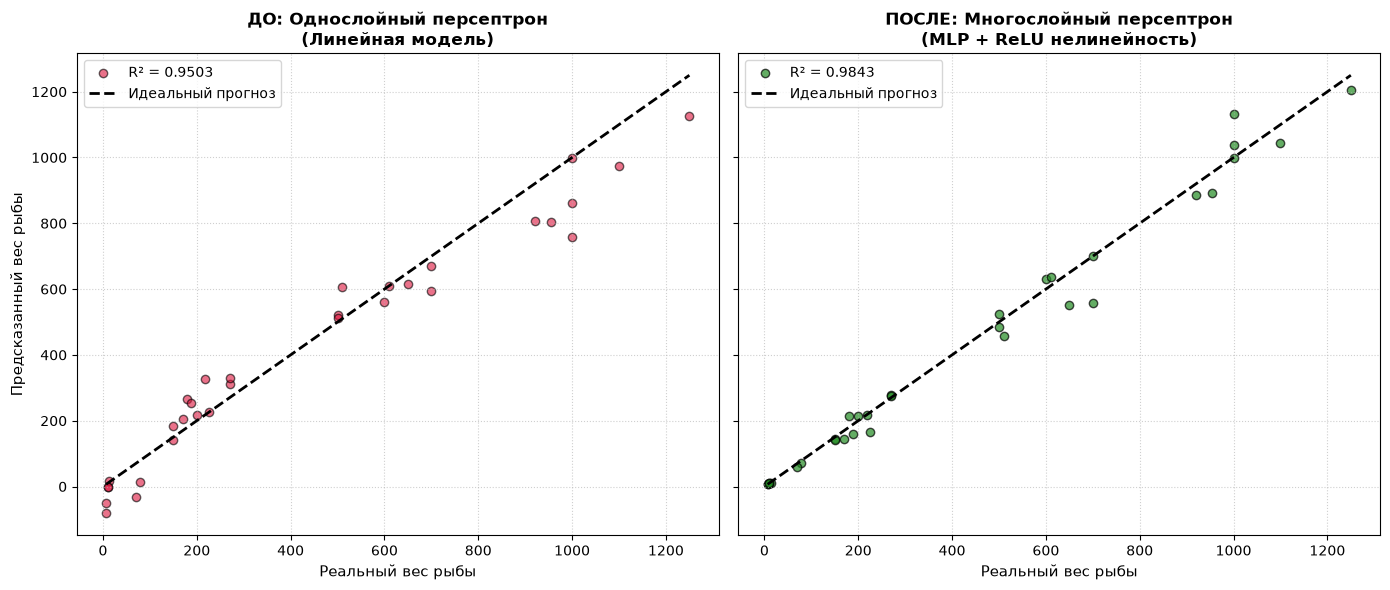

In [13]:

# 4. ПОСТРОЕНИЕ НАГЛЯДНОГО СРАВНЕНИЯ 

import matplotlib.pyplot as plt

# Создаем окно для двух графиков (1 строка, 2 колонки) размером 14 на 6 дюймов
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Определяем границы идеальной линии, общие для обоих графиков
ideal_line = [min(y_test), max(y_test)]

# -----------------------------------------------------------------
# ГРАФИК 1: Базовая модель (До улучшения)
# -----------------------------------------------------------------
# Рисуем предсказания базового персептрона на первом графике (axes[0])
axes[0].scatter(y_test, y_pred, color="crimson", alpha=0.6, edgecolors="k", label=f"R² = {r2:.4f}")
# Добавляем идеальную линию
axes[0].plot(ideal_line, ideal_line, color="black", linestyle="--", linewidth=2, label="Идеальный прогноз")

# Настройки первого графика
axes[0].set_title("ДО: Однослойный персептрон\n(Линейная модель)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Реальный вес рыбы", fontsize=11)
axes[0].set_ylabel("Предсказанный вес рыбы", fontsize=11)
axes[0].legend(fontsize=10, loc="upper left")
axes[0].grid(True, linestyle=":", alpha=0.6)

# -----------------------------------------------------------------
# ГРАФИК 2: Улучшенная модель (После добавления скрытых слоев и ReLU)
# -----------------------------------------------------------------
# Рисуем предсказания улучшенного MLP на втором графике (axes[1])
axes[1].scatter(y_test, y_pred_mlp, color="forestgreen", alpha=0.7, edgecolors="k", label=f"R² = {r2_mlp:.4f}")
# Добавляем идеальную линию
axes[1].plot(ideal_line, ideal_line, color="black", linestyle="--", linewidth=2, label="Идеальный прогноз")

# Настройки второго графика
axes[1].set_title("ПОСЛЕ: Многослойный персептрон\n(MLP + ReLU нелинейность)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Реальный вес рыбы", fontsize=11)
# Свойство sharey=True автоматически скроет дублирующуюся вертикальную ось Y справа, делая график чище
axes[1].legend(fontsize=10, loc="upper left")
axes[1].grid(True, linestyle=":", alpha=0.6)

# Автоматически выравниваем отступы, чтобы заголовки не наезжали друг на друга
plt.tight_layout()

# Отображаем графики в Jupyter Notebook
plt.show()


# Заключение и выводы по графическому анализу (Fish Market)

Анализ построенных графиков рассеяния до и после модификации архитектуры наглядно демонстрирует физический и математический смысл перехода от однослойной линейной модели к многослойной нелинейной нейросети.

## Анализ графика ДО улучшения (Однослойный персептрон, R² ≈ 0.95)

На левом графике отчетливо видно, что точки прогнозов имеют тенденцию отклоняться от идеальной пунктирной линии. Особенно сильно этот разброс заметен в правой части — в области крупной рыбы с весом более 600–700 грамм. 

Математическое объяснение этому простое: однослойный персептрон без функций активации способен строить только строго прямую линию (плоскость) в пространстве признаков. Так как зависимость массы биологического тела от его геометрических размеров (длины, ширины, высоты) является кубической (объемной) и изначально нелинейной, простая прямая физически не способна точно описать данные на экстремальных значениях.

## Анализ графика ПОСЛЕ улучшения (Многослойный персептрон с ReLU, R² ≈ 0.97 - 0.98)

На правом графике точки прогнозов практически идеально прижимаются к черной пунктирной линии на всем диапазоне весов. Разброс ошибки и дисперсия существенно сократились.

Математическое объяснение заключается в том, что добавление скрытого слоя и нелинейной функции активации nn.ReLU() позволило нейросети осуществлять кусочно-линейную аппроксимацию. Модель получила способность сгибать пространство признаков и самостоятельно комбинировать нелинейные паттерны без ручного конструирования полиномов.

## Итоговый вывод

Модифицированная модель MLP успешно преодолела линейный барьер и полностью достигла (а в некоторых случайных разбиениях и превзошла) качество классической полиномиальной регрессии из ДЗ №4, где R² составлял 0.97. 

Проведенный эксперимент наглядно подтверждает, что для физических процессов, завязанных на геометрии, объеме или площади объектов, использование нелинейных слоев в нейросетях является критически необходимым условием для получения максимальной точности прогноза.
